# Import and process data

Decided to filter out EANs where yearly consumption is below 365 kWh

In [1]:
import pandas as pd

df = pd.read_csv("data/part-00000-3895d355-7ed8-4cff-a072-bdc8805c8651-c000.csv")
df.head()

/var/folders/3v/7jmt0yfn07g4fc98xv_l001h0000gn/T/ipykernel_58583/872343793.py:3: DtypeWarning: Columns (13,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/part-00000-3895d355-7ed8-4cff-a072-bdc8805c8651-c000.csv")


,ean_anon,meterid_anon,measuredatetime,measure_inj,measure_av_inj,unit_inj,unit_av_inj,measure_cons,measure_av_cons,unit_cons,...,addressCity,addressCode,addressStreet,puissance,cabineTyp,totalTfo,tfoDesc,tfoTyp,sectorId,raccordClient_hist
0,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,6cf32997741fdd3b55700bd73bdf80c4c90c1dfa4da95f...,2024-11-01T00:00:00.000Z,0.003,NaN,KWH,KW,621.306,NaN,KWH,...,Bressoux,4020,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400
1,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,6cf32997741fdd3b55700bd73bdf80c4c90c1dfa4da95f...,2024-11-01T00:15:00.000Z,0.003,0.0,KWH,KW,621.317,0.044,KWH,...,Bressoux,4020,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400
2,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,6cf32997741fdd3b55700bd73bdf80c4c90c1dfa4da95f...,2024-11-01T00:30:00.000Z,0.003,0.0,KWH,KW,621.324,0.028,KWH,...,Bressoux,4020,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400
3,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,6cf32997741fdd3b55700bd73bdf80c4c90c1dfa4da95f...,2024-11-01T00:45:00.000Z,0.003,0.0,KWH,KW,621.335,0.044,KWH,...,Bressoux,4020,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400
4,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,6cf32997741fdd3b55700bd73bdf80c4c90c1dfa4da95f...,2024-11-01T01:00:00.000Z,0.003,0.0,KWH,KW,621.342,0.028,KWH,...,Bressoux,4020,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400


In [2]:
# get unique values in the ean_anon column
unique_eans = df['ean_anon'].unique()
print(f'There are {len(unique_eans)} distinct EANs.')

There are 38 distinct EANs.


In [3]:
# drop EANs whose total metered consumption (max−min) is below 365 kWh
total_cons = df.groupby('ean_anon')['measure_cons'] \
               .agg(lambda s: s.max() - s.min())
keep_eans = total_cons[total_cons >= 365].index

df = df[df['ean_anon'].isin(keep_eans)].copy()

# refresh any helper arrays that depend on the set of EANs
unique_eans = df['ean_anon'].unique()
ean_index_map = {ean: idx for idx, ean in enumerate(unique_eans)}

print(f"kept {len(unique_eans)} EANs (removed {len(total_cons) - len(unique_eans)})")

kept 33 EANs (removed 5)


# Identify street names

In [4]:
# extract the street name that goes with each EAN
# (there are many rows per EAN, but the street should be constant)
ean_streets = df[['ean_anon', 'addressStreet']].drop_duplicates()

# if you want to see them in the same order as `unique_eans`
ean_streets['ean_index'] = ean_streets['ean_anon'].map(ean_index_map)
ean_streets.sort_values('ean_index', inplace=True)

ean_streets


,ean_anon,addressStreet,ean_index
0,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,Avenue Joseph-Merlot,0
35040,03a56823cd32383d5b424a035f56ec245eb8043365df4e...,Avenue Joseph-Merlot,1
52271,05cf5079995c311593f357c6497d7c42989fcb1e35b340...,Avenue Joseph-Merlot,2
87311,06addb99531e0cae9f57abe22e0e84327d0fe7b2fc7431...,Avenue Joseph-Merlot,3
102439,076238e28776d9a7c66b679575ff43d00b2af42d4e975a...,Avenue Joseph-Merlot,4
137479,08e9089c5ce5122087e9cb0ec7d3c76e4221346a1a5597...,Avenue Joseph-Merlot,5
172519,0a5ee1ef564bfe6943ef9905688f975b0b12b9e9cc681f...,Plateau du Bouhay,6
207559,0a97396daa8fc2ff6985aad7fbb50d944cb86b50538fca...,Rue Ernest Malvoz,7
218088,0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a5...,Avenue Joseph-Merlot,8
253128,11c176d86d3b465c2cdd10a087aee4acd673f914020595...,Plateau du Bouhay,9


In [5]:

street_names = ean_streets['addressStreet'].unique()
street_names

array(['Avenue Joseph-Merlot', 'Plateau du Bouhay', 'Rue Ernest Malvoz'],
      dtype=object)

# Plot average, min and max daily profiles

In [6]:
import matplotlib.pyplot as plt

def plot_daily_pattern(index, data=df):
    """
    Plot the average daily pattern with min/max envelopes for a given EAN.
    
    Parameters:
    ean (str): The EAN value to filter
    data (DataFrame): The dataframe to use (default: df)
    """
    ean = unique_eans[index]
    
    # Filter data for the specific EAN
    ean_data = data[data['ean_anon'] == ean].copy()
    
    # Convert measuredatetime to datetime
    ean_data['measuredatetime'] = pd.to_datetime(ean_data['measuredatetime'])
    
    # Extract time of day (hour and minute)
    ean_data['time_of_day'] = ean_data['measuredatetime'].dt.time
    
    # sort by datetime, compute first difference of measure_cons and drop the first NaN row
    ean_data.sort_values('measuredatetime', inplace=True)
    ean_data['power_cons'] = ean_data['measure_cons'].diff()*4
    ean_data = ean_data.iloc[1:].copy()
    
    # Group by time of day and calculate mean, min, max of measure_cons
    daily_pattern = ean_data.groupby('time_of_day')['power_cons'].agg(['mean', 'min', 'max'])
    
    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(daily_pattern)), daily_pattern['mean'], label='Average', linewidth=2)
    plt.fill_between(range(len(daily_pattern)), daily_pattern['min'], daily_pattern['max'], 
                     alpha=0.3, label='Min/Max Envelope')
    
    plt.xlabel('Time of Day')
    plt.ylabel('Consumption (power_cons) [kW]')
    plt.title(f'Daily Pattern for EAN index: {index}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return ean_data


In [7]:
import matplotlib.pyplot as plt

def plot_daily_pattern(index, data=df):
    """
    Plot the average daily pattern with min/max envelopes for a given EAN.
    
    Parameters:
    ean (str): The EAN value to filter
    data (DataFrame): The dataframe to use (default: df)
    """
    ean = unique_eans[index]
    
    # Filter data for the specific EAN
    ean_data = data[data['ean_anon'] == ean].copy()
    
    # Convert measuredatetime to datetime
    ean_data['measuredatetime'] = pd.to_datetime(ean_data['measuredatetime'])
    
    # Extract time of day (hour and minute)
    ean_data['time_of_day'] = ean_data['measuredatetime'].dt.time
    
    # sort by datetime, compute first difference of measure_cons and drop the first NaN row
    ean_data.sort_values('measuredatetime', inplace=True)
    ean_data['power_cons'] = ean_data['measure_cons'].diff()*4
    ean_data = ean_data.iloc[1:].copy()
    
    # Group by time of day and calculate mean, min, max of measure_cons
    daily_pattern = ean_data.groupby('time_of_day')['power_cons'].agg(['mean', 'min', 'max'])
    
    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(daily_pattern)), daily_pattern['mean'], label='Average', linewidth=2)
    plt.fill_between(range(len(daily_pattern)), daily_pattern['min'], daily_pattern['max'], 
                     alpha=0.3, label='Min/Max Envelope')
    
    plt.xlabel('Time of Day')
    plt.ylabel('Consumption (power_cons) [kW]')
    plt.title(f'Daily Pattern for EAN index: {index}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return ean_data


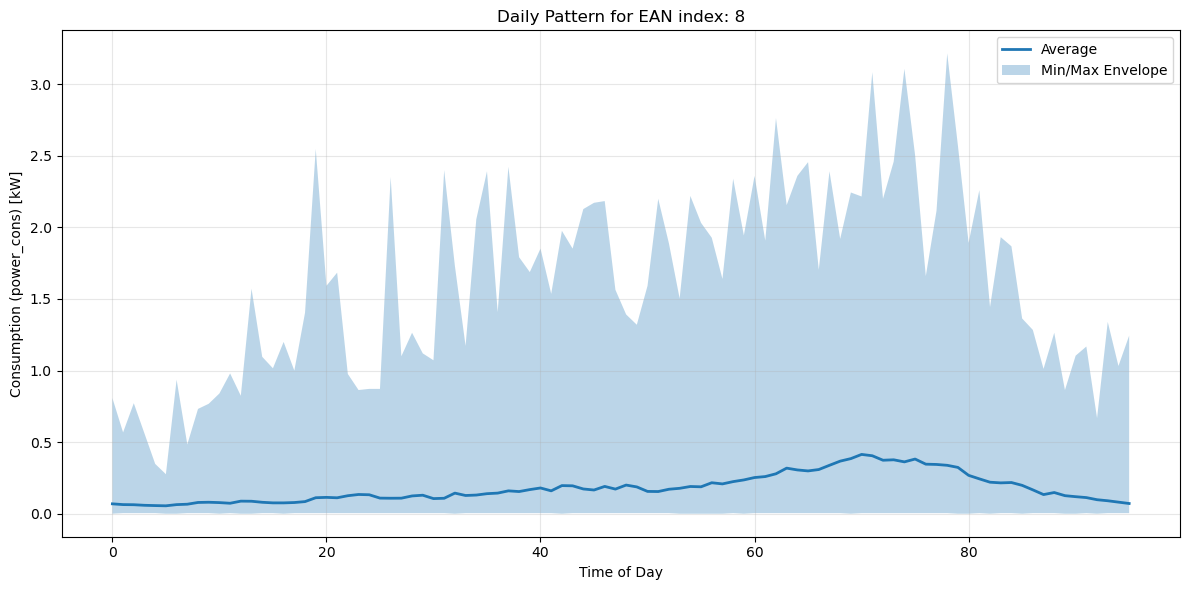

In [8]:
ean_data = plot_daily_pattern(8)

In [9]:
ean_data.head()

,ean_anon,meterid_anon,measuredatetime,measure_inj,measure_av_inj,unit_inj,unit_av_inj,measure_cons,measure_av_cons,unit_cons,...,addressStreet,puissance,cabineTyp,totalTfo,tfoDesc,tfoTyp,sectorId,raccordClient_hist,time_of_day,power_cons
218089,0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a5...,055734646f9ccee29045de1938f0e31140a40363c171d1...,2024-11-01 00:15:00+00:00,0.018,0.0,KWH,KW,837.144,0.124,KWH,...,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400,00:15:00,0.124
218090,0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a5...,055734646f9ccee29045de1938f0e31140a40363c171d1...,2024-11-01 00:30:00+00:00,0.018,0.0,KWH,KW,837.173,0.116,KWH,...,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400,00:30:00,0.116
218091,0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a5...,055734646f9ccee29045de1938f0e31140a40363c171d1...,2024-11-01 00:45:00+00:00,0.018,0.0,KWH,KW,837.202,0.116,KWH,...,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400,00:45:00,0.116
218092,0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a5...,055734646f9ccee29045de1938f0e31140a40363c171d1...,2024-11-01 01:00:00+00:00,0.018,0.0,KWH,KW,837.228,0.104,KWH,...,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400,01:00:00,0.104
218093,0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a5...,055734646f9ccee29045de1938f0e31140a40363c171d1...,2024-11-01 01:15:00+00:00,0.018,0.0,KWH,KW,837.234,0.024,KWH,...,Avenue Joseph-Merlot,400,CABINE RESEAU,1,NaN,NaN,6.206300e+116,1N400,01:15:00,0.024


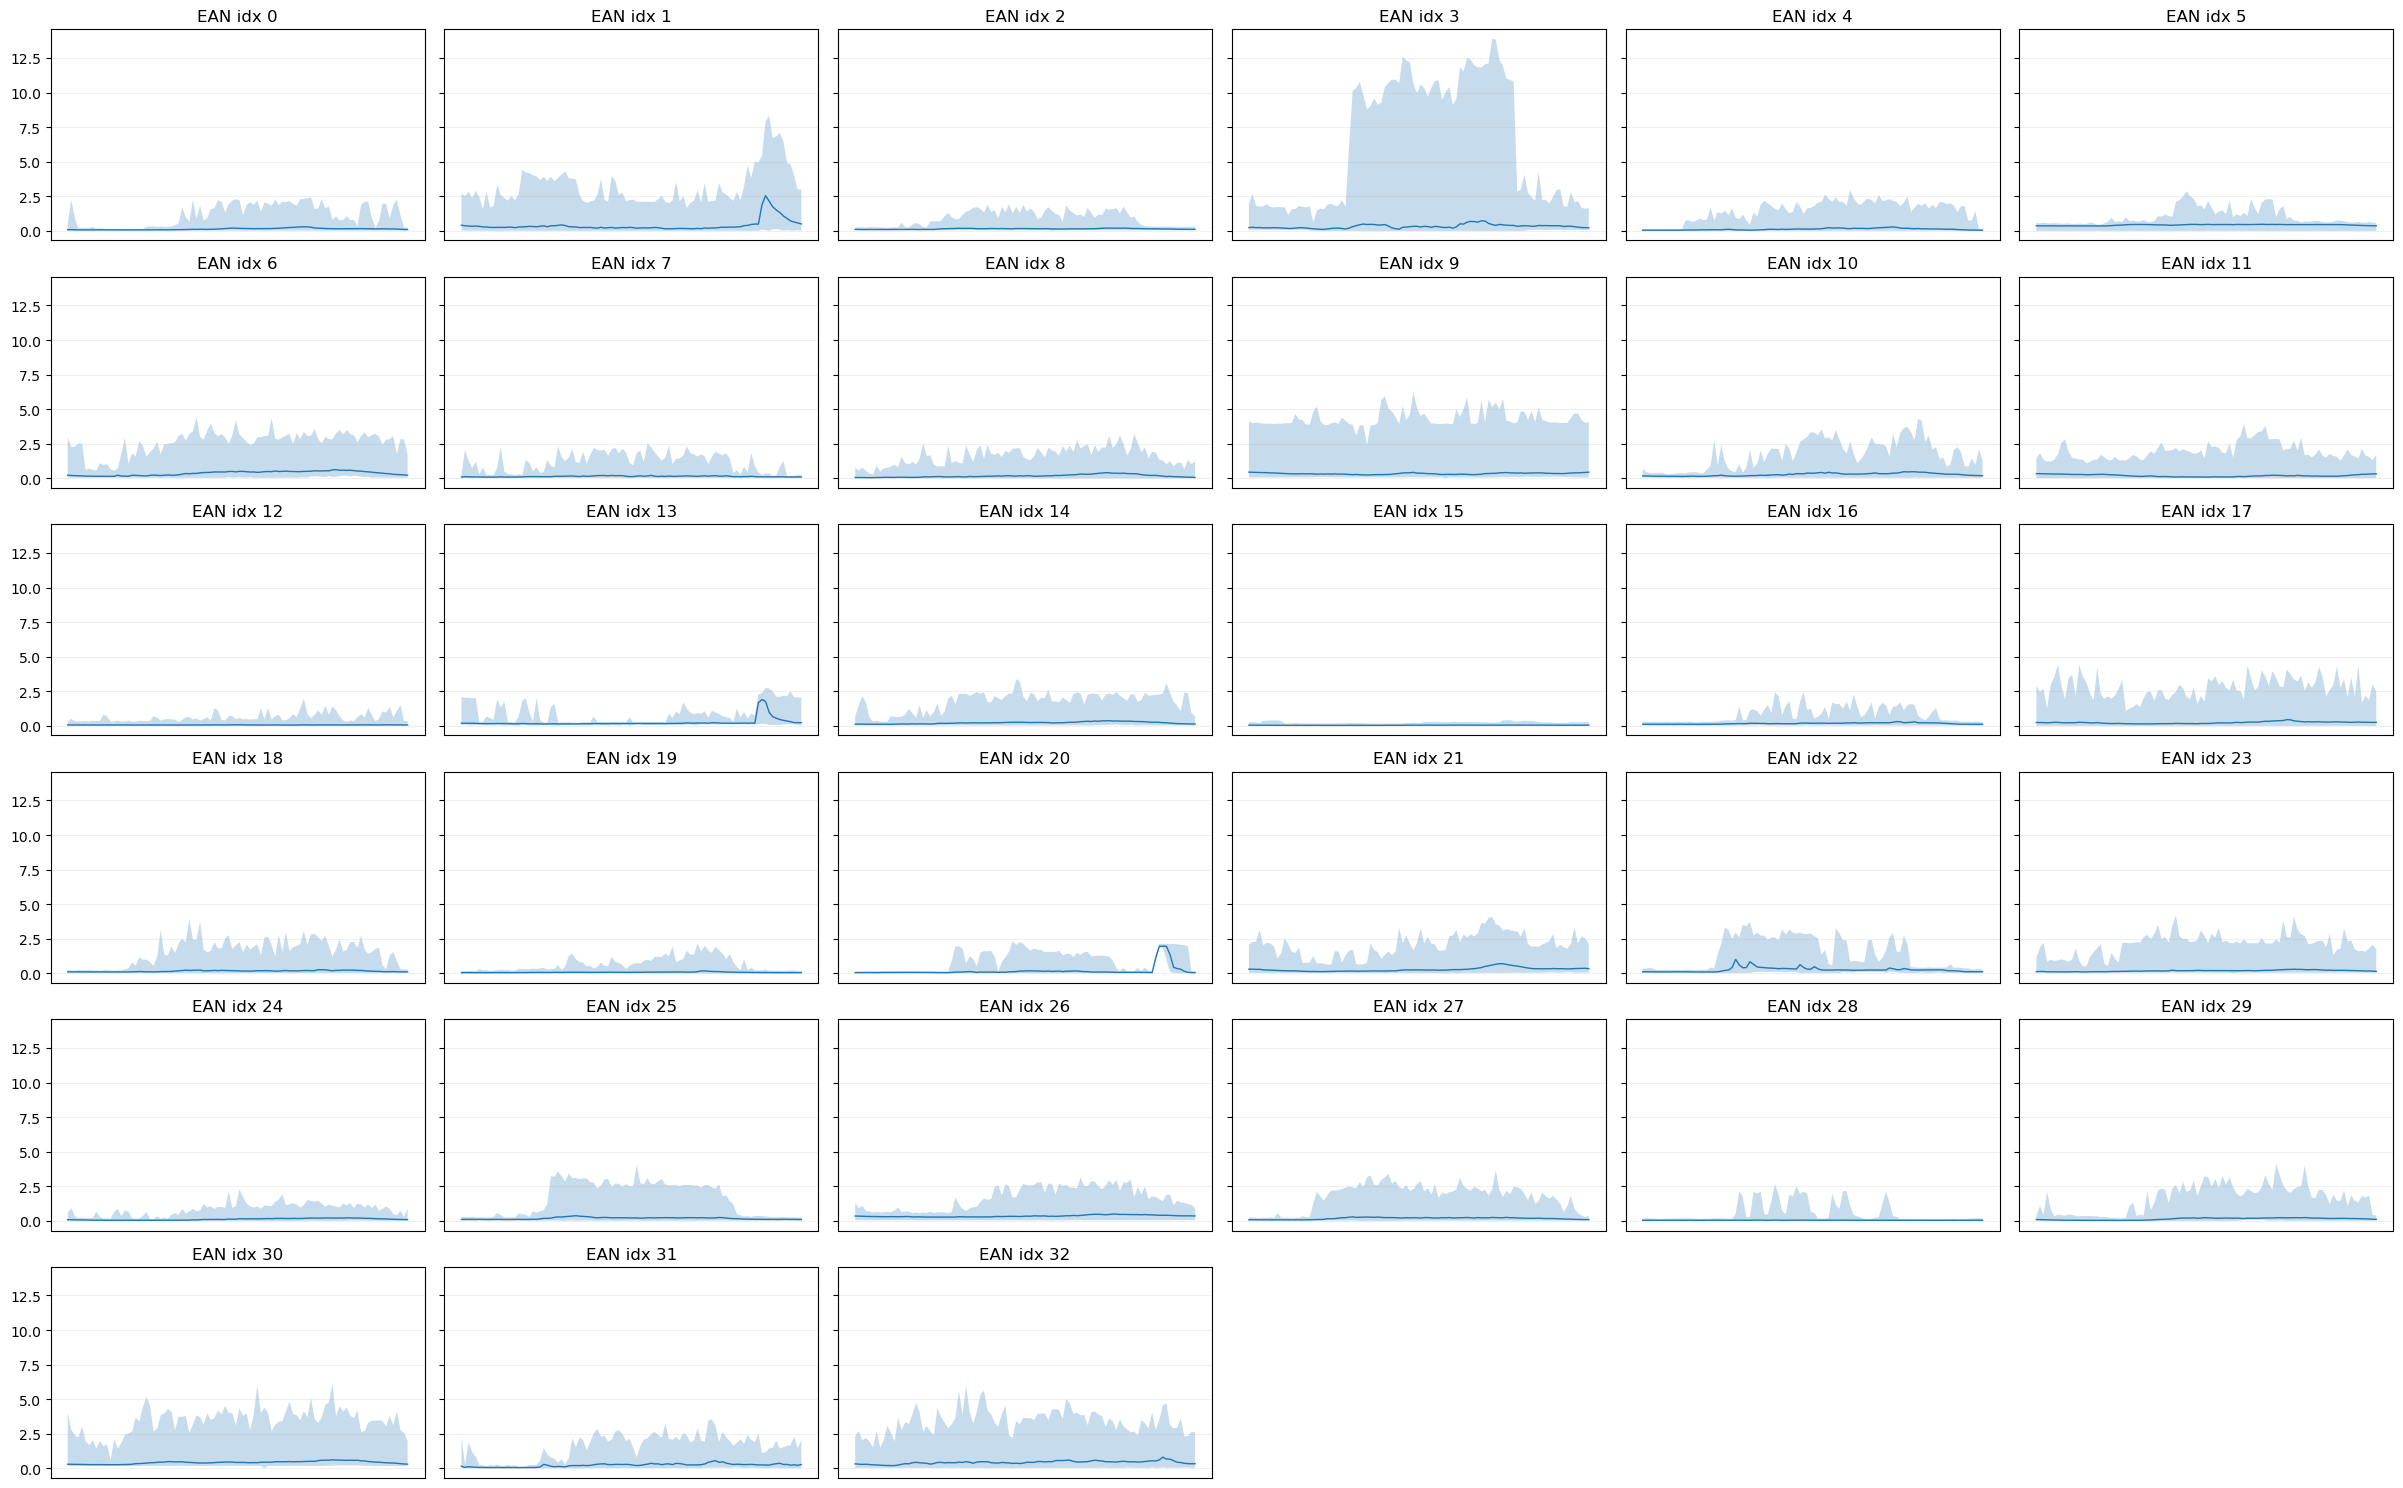

In [10]:
import math

def plot_daily_pattern_ax(index, ax, data=df):
    ean = unique_eans[index]
    ean_data = data[data['ean_anon'] == ean].copy()
    ean_data['measuredatetime'] = pd.to_datetime(ean_data['measuredatetime'])
    ean_data.sort_values('measuredatetime', inplace=True)
    ean_data['time_of_day'] = ean_data['measuredatetime'].dt.time
    ean_data['power_cons'] = ean_data['measure_cons'].diff()*4
    ean_data = ean_data.iloc[1:].copy()
    daily_pattern = ean_data.groupby('time_of_day')['power_cons'].agg(['mean', 'min', 'max']).sort_index()

    x = range(len(daily_pattern))
    ax.plot(x, daily_pattern['mean'], label='Average', linewidth=1)
    ax.fill_between(x, daily_pattern['min'], daily_pattern['max'], alpha=0.25)
    ax.set_title(f"EAN idx {index}")
    ax.set_xticks([])
    ax.grid(True, alpha=0.2)

n = len(unique_eans)
ncols = int(math.ceil(math.sqrt(n)))
nrows = int(math.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, max(3, nrows * 2.5)), sharey=True)
axes = axes.flatten()

for i in range(n):
    plot_daily_pattern_ax(i, axes[i])

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

# Plot yearly consumptions 

364 days 23:45:00


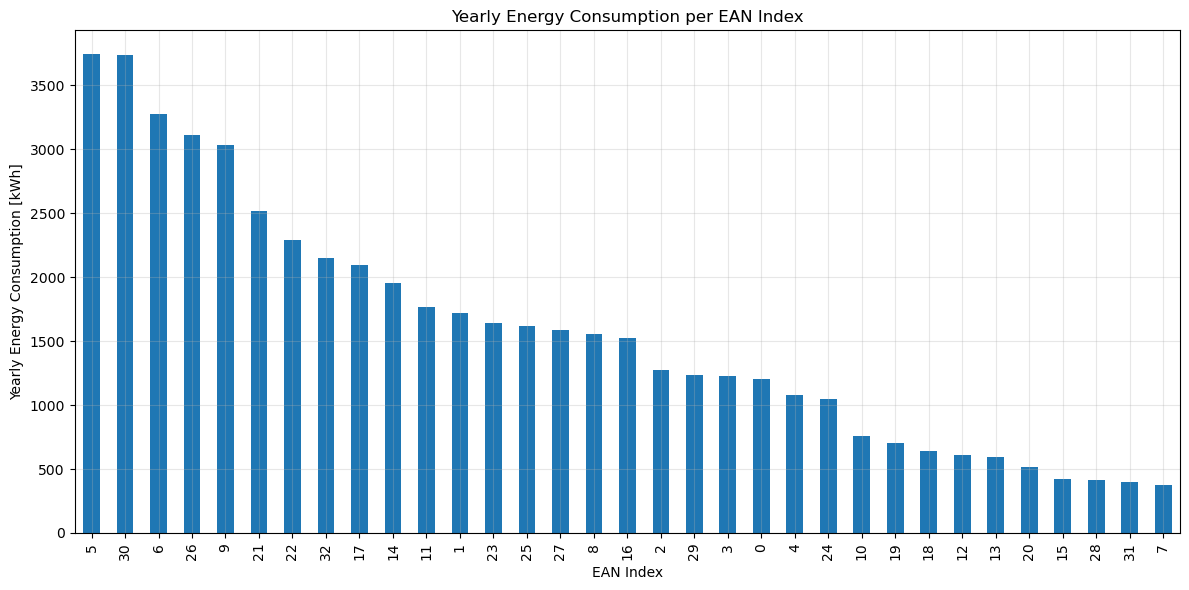

In [11]:

# Convert measuredatetime to datetime if not already
df['measuredatetime'] = pd.to_datetime(df['measuredatetime'])

print(df['measuredatetime'].max() - df['measuredatetime'].min())

# Extract year
df['year'] = df['measuredatetime'].dt.year

# Group by EAN and year, sum consumption
yearly_cons = df.groupby(['ean_anon', 'year'])['measure_cons'].max() - df.groupby(['ean_anon', 'year'])['measure_cons'].min()
yearly_cons = yearly_cons.reset_index()

# Pivot to get EAN index as x-axis
ean_index_map = {ean: idx for idx, ean in enumerate(unique_eans)}
yearly_cons['ean_index'] = yearly_cons['ean_anon'].map(ean_index_map)

# Aggregate yearly consumption per EAN index (sum over years if multiple)
ean_yearly_sum = yearly_cons.groupby('ean_index')['measure_cons'].sum()

ean_yearly_sum.sort_values(ascending=False, inplace=True)


plt.figure(figsize=(12, 6))
ean_yearly_sum.plot(kind='bar')
plt.xlabel('EAN Index')
plt.ylabel('Yearly Energy Consumption [kWh]')
plt.title('Yearly Energy Consumption per EAN Index')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


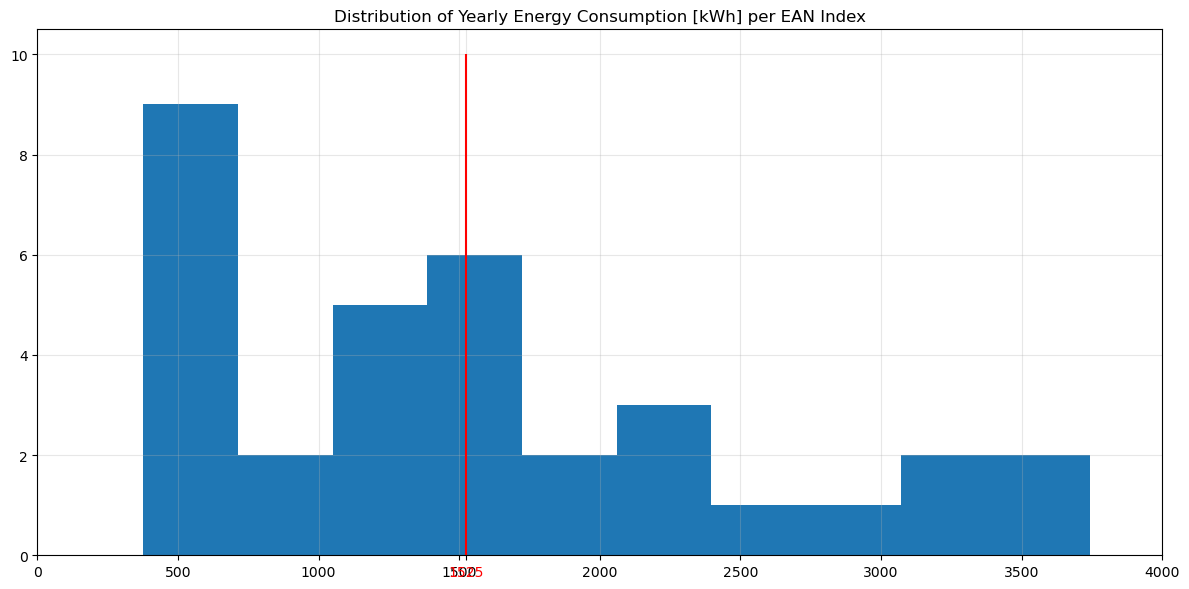

In [12]:
plt.figure(figsize=(12, 6))
ean_yearly_sum.hist()
#plt.xlabel('EAN Index')
#plt.ylabel('Yearly Energy Consumption ')
plt.title('Distribution of Yearly Energy Consumption [kWh] per EAN Index')
plt.grid(True, alpha=0.3)
median_val = ean_yearly_sum.median()
plt.vlines(x=median_val, ymin=0, ymax=10, colors="red")
ax = plt.gca()
# add the median value to the current x‑ticks
ticks = list(ax.get_xticks())
ticks.append(median_val)
ax.set_xticks(ticks)
# make the tick label for the median red
ax.get_xticklabels()[-1].set_color('red')
plt.tight_layout()
plt.show()



In [13]:
ean_yearly_sum.mean()

np.float64(1570.0078484848484)

# Analyse des tensions

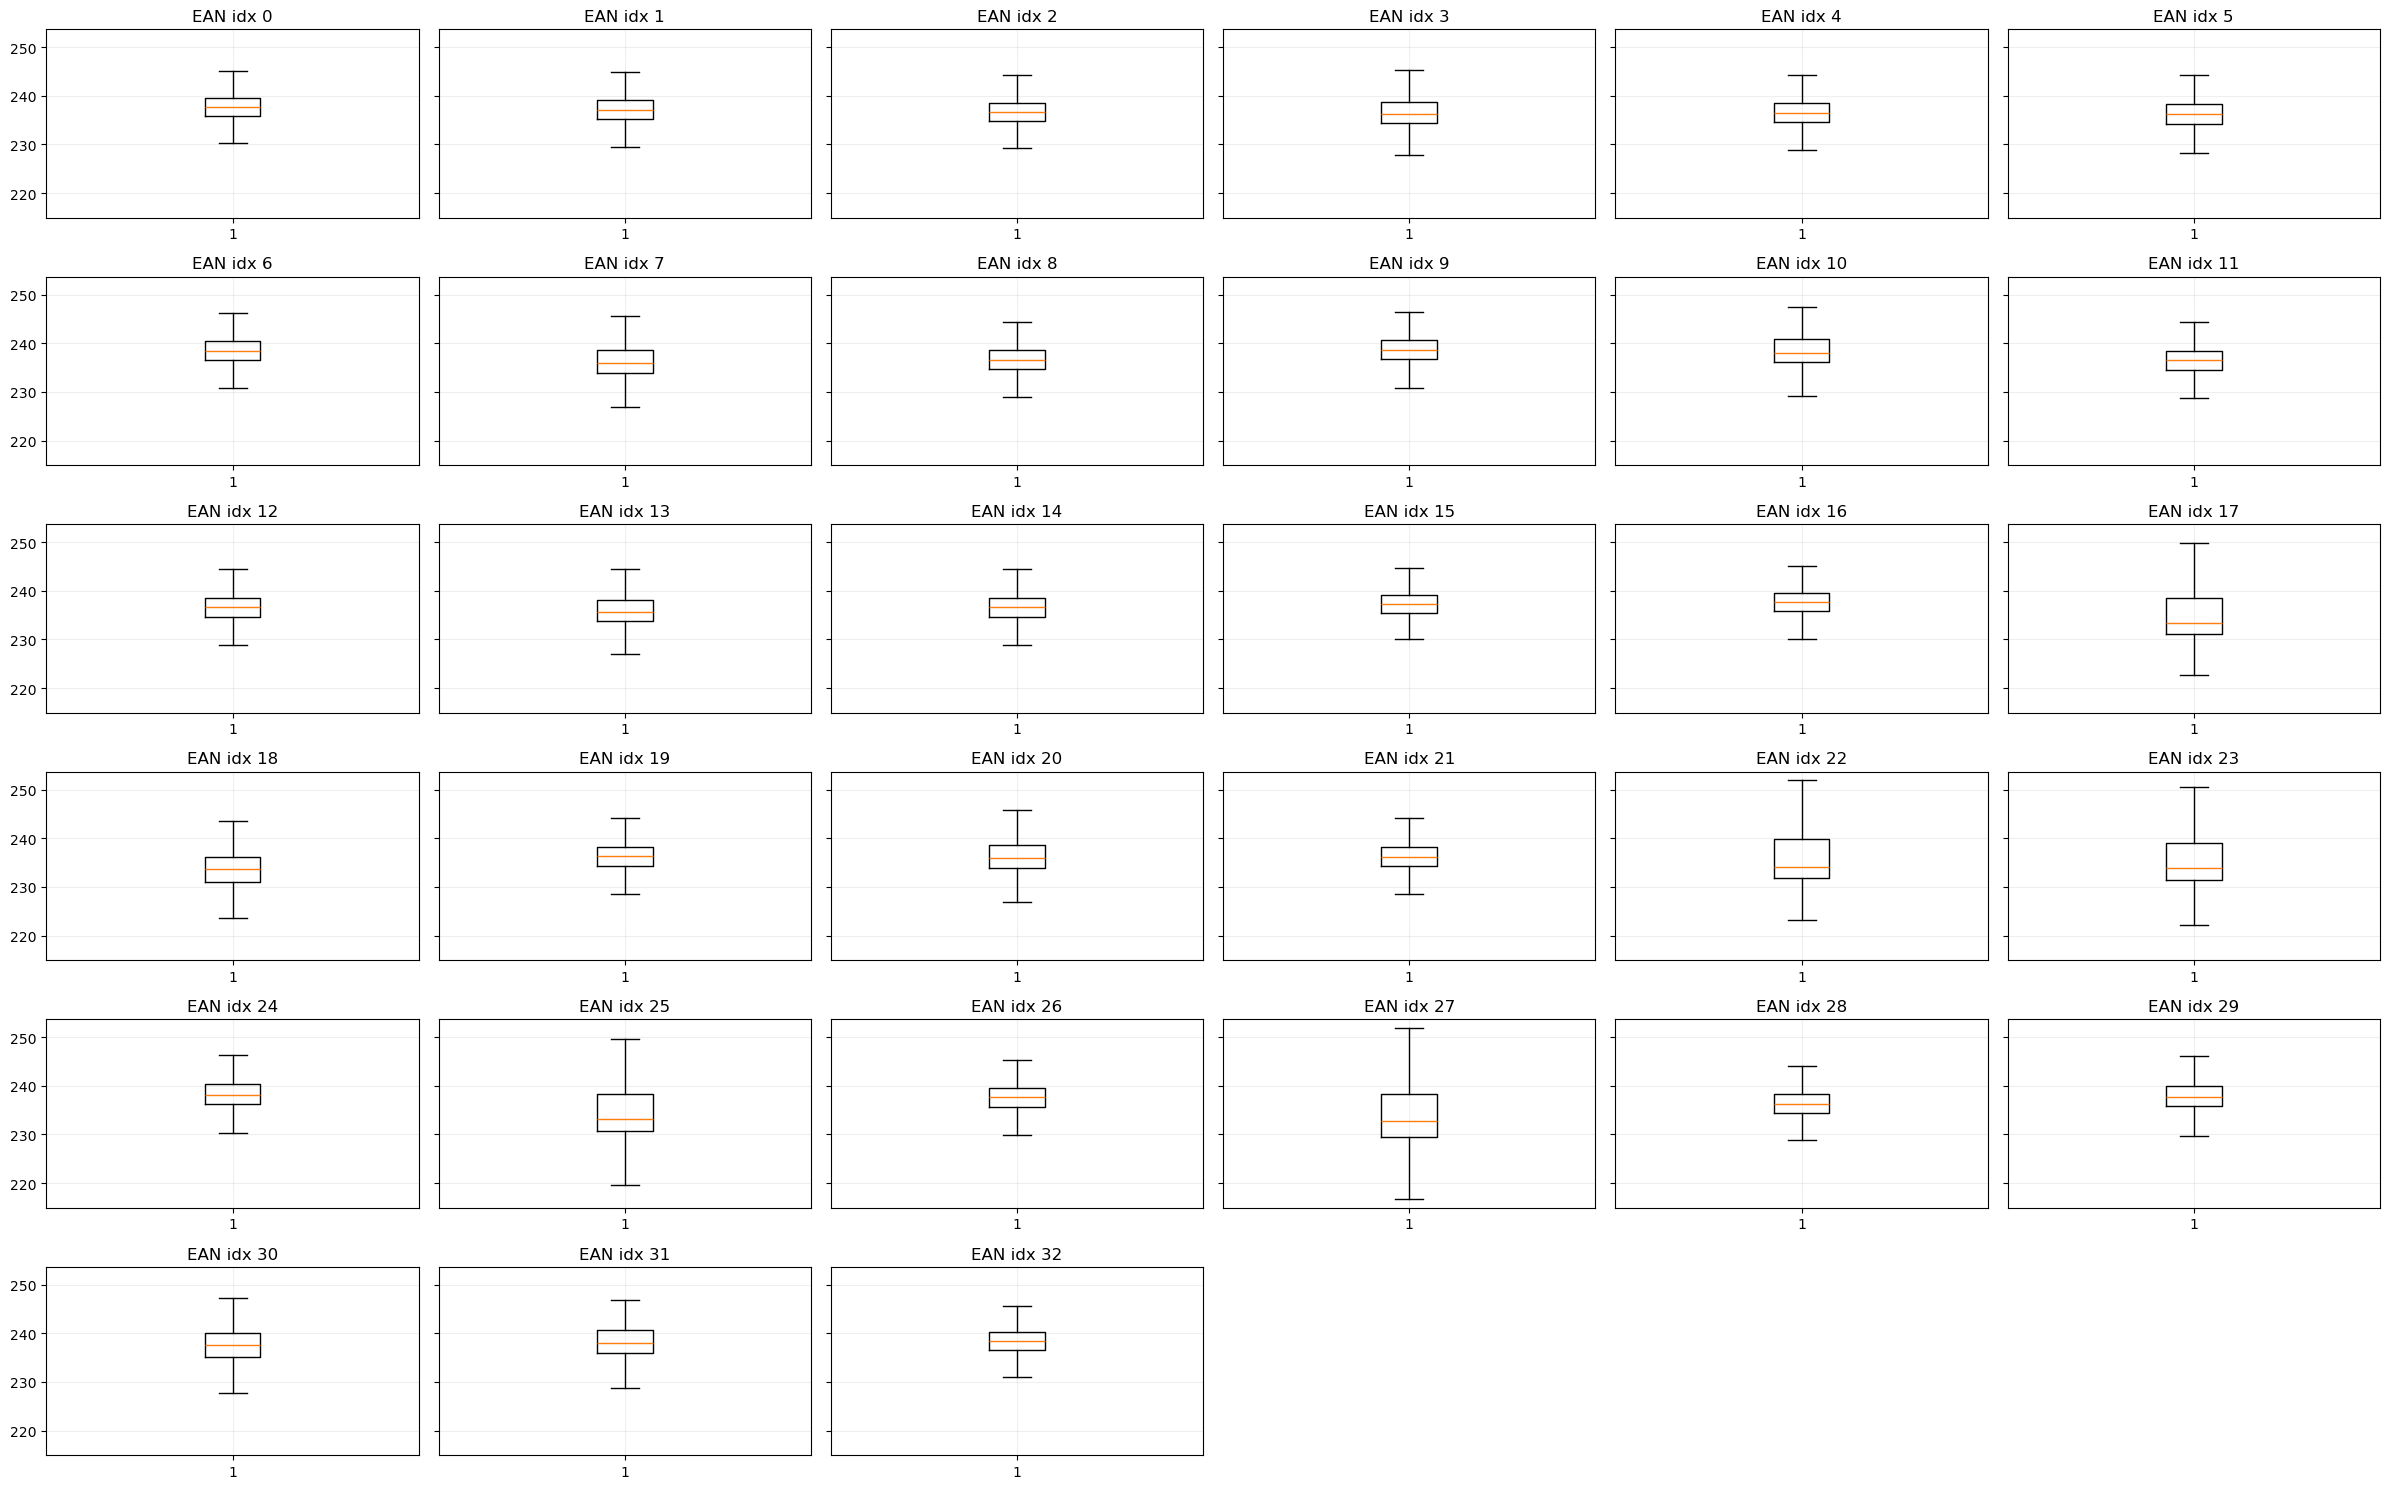

In [14]:
import math

import matplotlib.pyplot as plt

def plot_box_ph1_ax(index, ax, data=df):
    ean = unique_eans[index]
    ean_data = data[data['ean_anon'] == ean]['measure_ph1'].dropna()
    if not ean_data.empty:
        ax.boxplot(ean_data, showfliers=False)
        ax.set_title(f"EAN idx {index}")
        ax.grid(True, alpha=0.2)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center', va='center')
        ax.set_title(f"EAN idx {index}")

n = len(unique_eans)
ncols = int(math.ceil(math.sqrt(n)))
nrows = int(math.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, max(3, nrows * 2.5)), sharey=True)
axes = axes.flatten()

for i in range(n):
    plot_box_ph1_ax(i, axes[i])

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [15]:
## Tentative de clustering, à analyser 
import sklearn.cluster

# Compute summary statistics for measure_ph1 per EAN
voltage_stats = df.groupby('ean_anon')['measure_ph1'].agg(['mean', 'std', 'min', 'max']).dropna()

# Add ean_index for reference
voltage_stats['ean_index'] = voltage_stats.index.map(ean_index_map)

# Prepare data for clustering (use mean, std, min, max as features)
features = voltage_stats[['mean', 'std', 'min', 'max']]

# Perform K-means clustering with 3 clusters
kmeans = sklearn.cluster.KMeans(n_clusters=3, random_state=42)
voltage_stats['cluster'] = kmeans.fit_predict(features)

# Display the clustered EANs
voltage_stats[['ean_index', 'cluster']].sort_values('ean_index')

,ean_index,cluster
ean_anon,,
00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7eb502690018bc04d3d,0,0
03a56823cd32383d5b424a035f56ec245eb8043365df4e9f88f2b753d0f14d1e,1,0
05cf5079995c311593f357c6497d7c42989fcb1e35b340724e189489c20c9adb,2,0
06addb99531e0cae9f57abe22e0e84327d0fe7b2fc7431a5b6db9451522bda02,3,1
076238e28776d9a7c66b679575ff43d00b2af42d4e975a9fedc937989b321636,4,0
08e9089c5ce5122087e9cb0ec7d3c76e4221346a1a55973712adb7434820a281,5,0
0a5ee1ef564bfe6943ef9905688f975b0b12b9e9cc681f8d501ce8c80aa1252e,6,1
0a97396daa8fc2ff6985aad7fbb50d944cb86b50538fca3424cd3082ce09cc32,7,0
0bd3dd8c2c11727d0b22b0dfc2d3bf343971939d6752a50f1d569f8f804868d5,8,0


## Positions GPS et affichage sur la carte

In [16]:
%pip install folium

Note: you may need to restart the kernel to use updated packages.


,ean_anon,year,measure_cons
0,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,2024,194.589
1,00f5dbd0a30e5ca52cc32f99135151124cf14d0b3642d7...,2025,1008.263
2,03a56823cd32383d5b424a035f56ec245eb8043365df4e...,2025,1717.378
3,05cf5079995c311593f357c6497d7c42989fcb1e35b340...,2024,229.508
4,05cf5079995c311593f357c6497d7c42989fcb1e35b340...,2025,1043.945
5,06addb99531e0cae9f57abe22e0e84327d0fe7b2fc7431...,2025,1225.074
6,076238e28776d9a7c66b679575ff43d00b2af42d4e975a...,2024,197.505
7,076238e28776d9a7c66b679575ff43d00b2af42d4e975a...,2025,878.108
8,08e9089c5ce5122087e9cb0ec7d3c76e4221346a1a5597...,2024,653.487
9,08e9089c5ce5122087e9cb0ec7d3c76e4221346a1a5597...,2025,3089.206


Saved yearly profiles to 'load_profiles.csv'
